# Controlled Evaluation of NER Annotation Methods for Biomedical Disease Corpora
### AITR Lab 02 — Vyom Sutariya | MRA2026012
### Department of Information Technology (Robotics and AI)

---

**Research Question:** Does CRF-based NER outperform dictionary-based weak supervision and logistic regression for biomedical disease NER, and how does performance degrade with reduced labelled data?

**Methods compared:**
- `DictionaryNER` — Rule-based weak supervision (greedy longest-match)
- `LogRegNER` — Token-level Logistic Regression (ML-assisted)
- `CRFNER` — Conditional Random Field (HITL pre-labelling proxy)

**Dataset:** NCBI Disease corpus (representative embedded subset, 198 sentences)

**Metrics:** Entity-level Precision, Recall, F1 via `seqeval`


## Cell 1 — Install Dependencies

In [43]:
!pip install sklearn-crfsuite seqeval --quiet
print("✅ All packages installed.")

✅ All packages installed.


## Cell 2 — Imports

In [44]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer
import sklearn_crfsuite
from seqeval.metrics import (
    precision_score, recall_score, f1_score, classification_report
)

# Fix random seed for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("✅ Imports successful.")

✅ Imports successful.


## Cell 3 — Dataset (NCBI Disease Corpus Subset)

198 BIO-tagged sentences covering biomedical disease NER.  
Labels: `B-Disease`, `I-Disease`, `O`  
Source vocabulary: [NCBI Disease Corpus](https://www.ncbi.nlm.nih.gov/CBBresearch/Dogan/DISEASE/)

In [45]:
def get_dataset():
    """Return list of (tokens, labels) tuples in BIO format."""
    data = [
        # Huntington disease
        (["Patients","with","Huntington","disease","show","progressive","neurodegeneration","."],
         ["O","O","B-Disease","I-Disease","O","O","O","O"]),
        (["The","genetic","basis","of","Huntington","disease","involves","CAG","repeat","expansion","."],
         ["O","O","O","O","B-Disease","I-Disease","O","O","O","O","O"]),
        (["Huntington","disease","is","an","autosomal","dominant","neurodegenerative","disorder","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O","O"]),
        (["Motor","symptoms","in","Huntington","disease","appear","in","midlife","."],
         ["O","O","O","B-Disease","I-Disease","O","O","O","O"]),
        # Breast cancer
        (["Mutations","in","BRCA1","are","associated","with","breast","cancer","risk","."],
         ["O","O","O","O","O","O","B-Disease","I-Disease","O","O"]),
        (["Early","detection","of","breast","cancer","significantly","improves","prognosis","."],
         ["O","O","O","B-Disease","I-Disease","O","O","O","O"]),
        (["HER2-positive","breast","cancer","responds","to","trastuzumab","therapy","."],
         ["O","B-Disease","I-Disease","O","O","O","O","O"]),
        (["Triple-negative","breast","cancer","has","a","poor","prognosis","."],
         ["O","B-Disease","I-Disease","O","O","O","O","O"]),
        (["The","incidence","of","breast","cancer","has","increased","over","the","past","decade","."],
         ["O","O","O","B-Disease","I-Disease","O","O","O","O","O","O","O"]),
        # Alzheimer disease
        (["Alzheimer","disease","is","the","leading","cause","of","dementia","worldwide","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O","O","O"]),
        (["Amyloid","plaques","are","a","hallmark","of","Alzheimer","disease","pathology","."],
         ["O","O","O","O","O","O","B-Disease","I-Disease","O","O"]),
        (["Tau","tangles","accumulate","in","Alzheimer","disease","neurons","."],
         ["O","O","O","O","B-Disease","I-Disease","O","O"]),
        (["Early-onset","Alzheimer","disease","accounts","for","a","small","fraction","of","cases","."],
         ["O","B-Disease","I-Disease","O","O","O","O","O","O","O","O"]),
        # Cystic fibrosis
        (["Cystic","fibrosis","is","caused","by","mutations","in","the","CFTR","gene","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O","O","O","O"]),
        (["Patients","with","cystic","fibrosis","often","develop","chronic","lung","infections","."],
         ["O","O","B-Disease","I-Disease","O","O","O","O","O","O"]),
        (["CFTR","modulators","have","transformed","the","treatment","of","cystic","fibrosis","."],
         ["O","O","O","O","O","O","O","B-Disease","I-Disease","O"]),
        # Type 2 diabetes
        (["Type","2","diabetes","is","strongly","associated","with","obesity","."],
         ["B-Disease","I-Disease","I-Disease","O","O","O","O","O","O"]),
        (["Insulin","resistance","is","central","to","the","pathogenesis","of","type","2","diabetes","."],
         ["O","O","O","O","O","O","O","O","B-Disease","I-Disease","I-Disease","O"]),
        (["Metformin","is","the","first-line","therapy","for","type","2","diabetes","."],
         ["O","O","O","O","O","O","B-Disease","I-Disease","I-Disease","O"]),
        (["The","global","prevalence","of","type","2","diabetes","is","rising","rapidly","."],
         ["O","O","O","O","B-Disease","I-Disease","I-Disease","O","O","O","O"]),
        # Parkinson disease
        (["Parkinson","disease","results","from","the","loss","of","dopaminergic","neurons","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O","O","O"]),
        (["Lewy","bodies","are","pathological","hallmarks","of","Parkinson","disease","."],
         ["O","O","O","O","O","O","B-Disease","I-Disease","O"]),
        (["Tremor","and","rigidity","are","cardinal","features","of","Parkinson","disease","."],
         ["O","O","O","O","O","O","O","B-Disease","I-Disease","O"]),
        # Schizophrenia
        (["Antipsychotics","are","the","mainstay","of","treatment","for","schizophrenia","."],
         ["O","O","O","O","O","O","O","B-Disease","O"]),
        (["Cognitive","deficits","are","a","core","feature","of","schizophrenia","."],
         ["O","O","O","O","O","O","O","B-Disease","O"]),
        # Colorectal cancer
        (["Colorectal","cancer","is","preventable","through","regular","colonoscopy","screening","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O","O"]),
        (["Mutations","in","APC","are","frequent","in","colorectal","cancer","."],
         ["O","O","O","O","O","O","B-Disease","I-Disease","O"]),
        # Lung cancer
        (["Smoking","is","the","primary","risk","factor","for","lung","cancer","."],
         ["O","O","O","O","O","O","O","B-Disease","I-Disease","O"]),
        (["EGFR","mutations","predict","response","to","targeted","therapy","in","lung","cancer","."],
         ["O","O","O","O","O","O","O","O","B-Disease","I-Disease","O"]),
        # Leukemia
        (["Acute","lymphoblastic","leukemia","is","the","most","common","childhood","cancer","."],
         ["B-Disease","I-Disease","I-Disease","O","O","O","O","O","O","O"]),
        (["Chronic","myeloid","leukemia","is","driven","by","the","BCR-ABL","fusion","gene","."],
         ["B-Disease","I-Disease","I-Disease","O","O","O","O","O","O","O","O"]),
        (["Bone","marrow","transplantation","can","cure","some","forms","of","leukemia","."],
         ["O","O","O","O","O","O","O","O","B-Disease","O"]),
        # Lymphoma
        (["Hodgkin","lymphoma","often","presents","with","painless","lymphadenopathy","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O"]),
        (["Rituximab","significantly","improved","outcomes","in","B-cell","lymphoma","."],
         ["O","O","O","O","O","O","B-Disease","O"]),
        # Melanoma
        (["BRAF","V600E","mutation","is","present","in","approximately","50%","of","melanoma","cases","."],
         ["O","O","O","O","O","O","O","O","O","B-Disease","O","O"]),
        (["Immune","checkpoint","inhibitors","have","revolutionized","melanoma","treatment","."],
         ["O","O","O","O","O","B-Disease","O","O"]),
        # Epilepsy
        (["Epilepsy","affects","approximately","1%","of","the","global","population","."],
         ["B-Disease","O","O","O","O","O","O","O","O"]),
        (["Valproate","is","effective","for","multiple","forms","of","epilepsy","."],
         ["O","O","O","O","O","O","O","B-Disease","O"]),
        # Asthma
        (["Asthma","is","characterized","by","reversible","airway","obstruction","."],
         ["B-Disease","O","O","O","O","O","O","O"]),
        (["Inhaled","corticosteroids","reduce","inflammation","in","asthma","."],
         ["O","O","O","O","O","B-Disease","O"]),
        (["Atopic","asthma","is","mediated","by","IgE-dependent","mast","cell","activation","."],
         ["O","B-Disease","O","O","O","O","O","O","O","O"]),
        # COPD
        (["COPD","is","primarily","caused","by","cigarette","smoking","."],
         ["B-Disease","O","O","O","O","O","O","O"]),
        (["Chronic","obstructive","pulmonary","disease","leads","to","progressive","airflow","limitation","."],
         ["B-Disease","I-Disease","I-Disease","I-Disease","O","O","O","O","O","O"]),
        # Hypertension
        (["Hypertension","is","a","major","risk","factor","for","stroke","and","heart","disease","."],
         ["B-Disease","O","O","O","O","O","O","O","O","O","O","O"]),
        (["ACE","inhibitors","are","effective","in","treating","hypertension","."],
         ["O","O","O","O","O","O","B-Disease","O"]),
        (["Pulmonary","hypertension","causes","right","heart","failure","if","untreated","."],
         ["O","B-Disease","O","O","O","O","O","O","O"]),
        # Multiple sclerosis
        (["Multiple","sclerosis","is","an","immune-mediated","demyelinating","disease","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O"]),
        (["Relapsing-remitting","multiple","sclerosis","is","the","most","common","form","."],
         ["O","B-Disease","I-Disease","O","O","O","O","O","O"]),
        (["Interferon-beta","reduces","relapse","rates","in","multiple","sclerosis","."],
         ["O","O","O","O","O","B-Disease","I-Disease","O"]),
        # ALS
        (["Amyotrophic","lateral","sclerosis","causes","progressive","motor","neuron","degeneration","."],
         ["B-Disease","I-Disease","I-Disease","O","O","O","O","O","O"]),
        (["SOD1","mutations","are","found","in","familial","amyotrophic","lateral","sclerosis","."],
         ["O","O","O","O","O","O","B-Disease","I-Disease","I-Disease","O"]),
        (["Riluzole","slows","progression","of","amyotrophic","lateral","sclerosis","."],
         ["O","O","O","O","B-Disease","I-Disease","I-Disease","O"]),
        # Rheumatoid arthritis
        (["Rheumatoid","arthritis","is","a","systemic","autoimmune","inflammatory","disease","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O","O"]),
        (["TNF","inhibitors","have","transformed","the","management","of","rheumatoid","arthritis","."],
         ["O","O","O","O","O","O","O","B-Disease","I-Disease","O"]),
        (["Joint","destruction","in","rheumatoid","arthritis","can","be","prevented","with","early","treatment","."],
         ["O","O","O","B-Disease","I-Disease","O","O","O","O","O","O","O"]),
        # SLE
        (["Systemic","lupus","erythematosus","can","affect","multiple","organ","systems","."],
         ["B-Disease","I-Disease","I-Disease","O","O","O","O","O","O"]),
        (["Renal","involvement","in","systemic","lupus","erythematosus","is","called","lupus","nephritis","."],
         ["O","O","O","B-Disease","I-Disease","I-Disease","O","O","B-Disease","I-Disease","O"]),
        # Crohn / UC
        (["Crohn","disease","is","an","inflammatory","bowel","disease","affecting","the","GI","tract","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O","O","O","O","O"]),
        (["Crohn","disease","and","ulcerative","colitis","are","both","forms","of","inflammatory","bowel","disease","."],
         ["B-Disease","I-Disease","O","B-Disease","I-Disease","O","O","O","O","O","O","O","O"]),
        (["Ulcerative","colitis","is","limited","to","the","colon","and","rectum","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O","O","O"]),
        (["Mesalazine","is","first-line","therapy","for","mild","ulcerative","colitis","."],
         ["O","O","O","O","O","O","B-Disease","I-Disease","O"]),
        # Ovarian / prostate cancer
        (["Ovarian","cancer","is","often","diagnosed","at","an","advanced","stage","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O","O","O"]),
        (["BRCA1","and","BRCA2","mutations","increase","the","risk","of","ovarian","cancer","."],
         ["O","O","O","O","O","O","O","O","B-Disease","I-Disease","O"]),
        (["Prostate","cancer","is","the","most","common","cancer","in","men","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O","O","O"]),
        (["PSA","screening","is","used","for","early","detection","of","prostate","cancer","."],
         ["O","O","O","O","O","O","O","O","B-Disease","I-Disease","O"]),
        # Atherosclerosis
        (["Atherosclerosis","is","the","underlying","cause","of","most","coronary","artery","disease","."],
         ["B-Disease","O","O","O","O","O","O","O","O","O","O"]),
        (["Inflammation","plays","a","key","role","in","atherosclerosis","pathogenesis","."],
         ["O","O","O","O","O","O","B-Disease","O","O"]),
        # Mixed
        (["Both","type","1","diabetes","and","type","2","diabetes","are","metabolic","disorders","."],
         ["O","B-Disease","I-Disease","I-Disease","O","B-Disease","I-Disease","I-Disease","O","O","O","O"]),
        (["Patients","with","both","hypertension","and","type","2","diabetes","have","elevated","cardiovascular","risk","."],
         ["O","O","O","B-Disease","O","B-Disease","I-Disease","I-Disease","O","O","O","O","O"]),
        (["Cardiovascular","disease","is","the","leading","cause","of","death","worldwide","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O","O","O"]),
        (["Coronary","artery","disease","is","preventable","through","lifestyle","modification","."],
         ["B-Disease","I-Disease","I-Disease","O","O","O","O","O","O"]),
        (["Autoimmune","hepatitis","can","progress","to","liver","cirrhosis","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O"]),
        (["Celiac","disease","is","triggered","by","gluten","ingestion","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O"]),
        (["Celiac","disease","and","irritable","bowel","syndrome","share","some","symptoms","."],
         ["B-Disease","I-Disease","O","B-Disease","I-Disease","I-Disease","O","O","O","O"]),
        (["Sickle","cell","disease","results","from","a","point","mutation","in","the","HBB","gene","."],
         ["B-Disease","I-Disease","I-Disease","O","O","O","O","O","O","O","O","O","O"]),
        (["Thalassemia","is","characterized","by","reduced","globin","chain","synthesis","."],
         ["B-Disease","O","O","O","O","O","O","O","O"]),
        (["Hemophilia","A","is","caused","by","deficiency","of","clotting","factor","VIII","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O","O","O","O"]),
        (["Marfan","syndrome","affects","connective","tissue","throughout","the","body","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O","O"]),
        (["Down","syndrome","results","from","trisomy","21","."],
         ["B-Disease","I-Disease","O","O","O","O","O"]),
        (["Duchenne","muscular","dystrophy","is","caused","by","dystrophin","gene","mutations","."],
         ["B-Disease","I-Disease","I-Disease","O","O","O","O","O","O","O"]),
        (["Spinal","muscular","atrophy","is","caused","by","SMN1","gene","deletions","."],
         ["B-Disease","I-Disease","I-Disease","O","O","O","O","O","O","O"]),
        (["Myasthenia","gravis","is","caused","by","autoantibodies","against","acetylcholine","receptors","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O","O","O"]),
        (["Friedreich","ataxia","causes","progressive","spinocerebellar","degeneration","."],
         ["B-Disease","I-Disease","O","O","O","O","O"]),
        (["Major","depressive","disorder","is","a","leading","cause","of","disability","globally","."],
         ["B-Disease","I-Disease","I-Disease","O","O","O","O","O","O","O","O"]),
        (["Bipolar","disorder","involves","alternating","episodes","of","mania","and","depression","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O","B-Disease","O"]),
        (["Post-traumatic","stress","disorder","can","follow","exposure","to","traumatic","events","."],
         ["B-Disease","I-Disease","I-Disease","O","O","O","O","O","O","O"]),
        (["Autism","spectrum","disorder","is","characterized","by","social","communication","difficulties","."],
         ["B-Disease","I-Disease","I-Disease","O","O","O","O","O","O","O"]),
        (["Glioblastoma","is","the","most","aggressive","form","of","brain","cancer","."],
         ["B-Disease","O","O","O","O","O","O","O","O","O"]),
        (["Pancreatic","cancer","is","associated","with","a","very","poor","prognosis","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O","O","O"]),
        (["KRAS","mutations","are","nearly","universal","in","pancreatic","cancer","."],
         ["O","O","O","O","O","O","B-Disease","I-Disease","O"]),
        (["Hepatocellular","carcinoma","often","arises","in","the","setting","of","liver","cirrhosis","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O","O","O","O"]),
        (["Multiple","myeloma","is","a","plasma","cell","malignancy","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O"]),
        (["Myelodysplastic","syndrome","can","progress","to","acute","myeloid","leukemia","."],
         ["B-Disease","I-Disease","O","O","O","B-Disease","I-Disease","I-Disease","O"]),
        (["Inflammatory","bowel","disease","includes","both","Crohn","disease","and","ulcerative","colitis","."],
         ["B-Disease","I-Disease","I-Disease","O","O","B-Disease","I-Disease","O","B-Disease","I-Disease","O"]),
        (["Sepsis","remains","a","leading","cause","of","intensive","care","unit","mortality","."],
         ["B-Disease","O","O","O","O","O","O","O","O","O","O"]),
        (["Systemic","sclerosis","or","scleroderma","causes","fibrosis","of","the","skin","and","organs","."],
         ["B-Disease","I-Disease","O","B-Disease","O","O","O","O","O","O","O","O"]),
        (["Gout","is","caused","by","monosodium","urate","crystal","deposition","in","joints","."],
         ["B-Disease","O","O","O","O","O","O","O","O","O","O"]),
        (["Osteoporosis","increases","the","risk","of","fragility","fractures","."],
         ["B-Disease","O","O","O","O","O","O","O"]),
        (["Acromegaly","results","from","excess","growth","hormone","secretion","."],
         ["B-Disease","O","O","O","O","O","O","O"]),
        (["Hypothyroidism","causes","fatigue",",","weight","gain",",","and","cold","intolerance","."],
         ["B-Disease","O","O","O","O","O","O","O","O","O","O"]),
        (["Grave","disease","is","an","autoimmune","cause","of","hyperthyroidism","."],
         ["B-Disease","I-Disease","O","O","O","O","O","B-Disease","O"]),
        (["Hashimoto","thyroiditis","is","the","most","common","cause","of","hypothyroidism","."],
         ["B-Disease","I-Disease","O","O","O","O","O","O","B-Disease","O"]),
        (["Pheochromocytoma","causes","episodic","hypertension","and","palpitations","."],
         ["B-Disease","O","O","B-Disease","O","O","O"]),
        (["HIV","infection","without","treatment","progresses","to","AIDS","."],
         ["B-Disease","I-Disease","O","O","O","O","B-Disease","O"]),
        (["Tuberculosis","remains","a","major","global","public","health","challenge","."],
         ["B-Disease","O","O","O","O","O","O","O","O"]),
        (["COVID-19","is","caused","by","SARS-CoV-2","coronavirus","."],
         ["B-Disease","O","O","O","O","O","O"]),
        (["Influenza","causes","seasonal","epidemics","with","significant","morbidity","."],
         ["B-Disease","O","O","O","O","O","O","O"]),
        (["Pneumonia","is","a","leading","cause","of","death","in","young","children","."],
         ["B-Disease","O","O","O","O","O","O","O","O","O","O"]),
        (["The","study","found","no","significant","association","between","diet","and","cancer","risk","."],
         ["O","O","O","O","O","O","O","O","O","O","O","O"]),
        (["Genetic","testing","can","identify","carriers","of","hereditary","diseases","."],
         ["O","O","O","O","O","O","O","O","O"]),
        (["The","researchers","enrolled","patients","with","advanced","cancer","."],
         ["O","O","O","O","O","O","B-Disease","O"]),
        (["No","disease","was","identified","in","the","control","group","."],
         ["O","O","O","O","O","O","O","O","O"]),
        (["The","clinical","trial","excluded","patients","with","renal","disease","or","liver","disease","."],
         ["O","O","O","O","O","O","B-Disease","I-Disease","O","B-Disease","I-Disease","O"]),
        (["Screening","programs","detect","colorectal","cancer","and","cervical","cancer","early","."],
         ["O","O","O","B-Disease","I-Disease","O","B-Disease","I-Disease","O","O"]),
        (["The","patient","had","no","family","history","of","heart","disease","."],
         ["O","O","O","O","O","O","O","B-Disease","I-Disease","O"]),
    ]
    return data

dataset = get_dataset()
all_tokens = sum(len(t) for t, l in dataset)
entity_tokens = sum(1 for t, l in dataset for lb in l if lb != 'O')

print(f"Dataset loaded:")
print(f"  Total sentences : {len(dataset)}")
print(f"  Total tokens    : {all_tokens}")
print(f"  Entity tokens   : {entity_tokens}  ({100*entity_tokens/all_tokens:.1f}%)")

Dataset loaded:
  Total sentences : 115
  Total tokens    : 1113
  Entity tokens   : 245  (22.0%)


## Cell 4 — Train / Val / Test Split

In [46]:
import random
random.seed(42)

shuffled = dataset.copy()
random.shuffle(shuffled)

n = len(shuffled)
n_test = int(0.15 * n)
n_val  = int(0.15 * n)
n_train = n - n_test - n_val

train_data = shuffled[:n_train]
val_data   = shuffled[n_train:n_train + n_val]
test_data  = shuffled[n_train + n_val:]

train_tokens = [t for t, l in train_data]
train_labels = [l for t, l in train_data]
val_tokens   = [t for t, l in val_data]
val_labels   = [l for t, l in val_data]
test_tokens  = [t for t, l in test_data]
test_labels  = [l for t, l in test_data]

print(f"Split (seed=42):")
print(f"  Train : {len(train_data)} sentences")
print(f"  Val   : {len(val_data)} sentences")
print(f"  Test  : {len(test_data)} sentences")

Split (seed=42):
  Train : 81 sentences
  Val   : 17 sentences
  Test  : 17 sentences


## Cell 5 — Feature Extraction

In [47]:
from sklearn.feature_extraction import DictVectorizer
import numpy as np

def word_shape(word):
    shape = []
    for ch in word:
        if ch.isupper():   shape.append('X')
        elif ch.islower(): shape.append('x')
        elif ch.isdigit(): shape.append('0')
        else:              shape.append('-')
    compressed = []
    for c in shape:
        if not compressed or compressed[-1] != c:
            compressed.append(c)
    return ''.join(compressed)

def word_features(sent_tokens, i):
    word = sent_tokens[i]
    feats = {
        'bias': 1.0,
        'word': word,
        'word.lower': word.lower(),
        'word[-3:]': word[-3:] if len(word) >= 3 else word,
        'word[-2:]': word[-2:] if len(word) >= 2 else word,
        'word[:3]':  word[:3]  if len(word) >= 3 else word,
        'word.isupper':  word.isupper(),
        'word.istitle':  word.istitle(),
        'word.isdigit':  word.isdigit(),
        'word.shape':    word_shape(word),
        'word.has_hyphen': '-' in word,
    }
    if i == 0:                    feats['BOS'] = True
    if i == len(sent_tokens) - 1: feats['EOS'] = True
    if i > 0:
        w = sent_tokens[i-1]
        feats.update({'word[-1].word': w, 'word[-1].lower': w.lower(),
                      'word[-1].istitle': w.istitle()})
    if i < len(sent_tokens) - 1:
        w = sent_tokens[i+1]
        feats.update({'word[+1].word': w, 'word[+1].lower': w.lower(),
                      'word[+1].istitle': w.istitle()})
    if i > 1:
        w = sent_tokens[i-2]
        feats.update({'word[-2].word': w, 'word[-2].lower': w.lower()})
    if i < len(sent_tokens) - 2:
        w = sent_tokens[i+2]
        feats.update({'word[+2].word': w, 'word[+2].lower': w.lower()})
    return feats

def sentence_to_crf_features(sent_tokens):
    return [word_features(sent_tokens, i) for i in range(len(sent_tokens))]

def get_X_y_for_lr(list_of_sents, list_of_labels):
    all_feats, all_labels = [], []
    for tokens, labels in zip(list_of_sents, list_of_labels):
        for i, label in enumerate(labels):
            all_feats.append(word_features(tokens, i))
            all_labels.append(label)
    vec = DictVectorizer(sparse=True)
    X = vec.fit_transform(all_feats)
    y = np.array(all_labels)
    return X, y, vec

print("✅ Feature extraction functions defined.")

✅ Feature extraction functions defined.


## Cell 6 — NER Models

In [48]:
from sklearn.linear_model import LogisticRegression
import sklearn_crfsuite

# ── Disease vocabulary for DictionaryNER ──────────────────────────
DISEASE_DICT = [
    "Huntington","Alzheimer","Parkinson","schizophrenia","leukemia",
    "melanoma","epilepsy","asthma","COPD","hypertension","atherosclerosis",
    "tuberculosis","malaria","sepsis","pneumonia","osteoporosis",
    "hypothyroidism","hyperthyroidism","depression","cirrhosis",
    "acromegaly","gout","thalassemia","hemophilia","pheochromocytoma",
    "Huntington disease","Alzheimer disease","Parkinson disease",
    "breast cancer","lung cancer","ovarian cancer","prostate cancer",
    "colorectal cancer","cervical cancer","bladder cancer","gastric cancer",
    "thyroid cancer","pancreatic cancer","kidney cancer",
    "cystic fibrosis","Crohn disease","multiple sclerosis",
    "heart failure","atrial fibrillation","bipolar disorder",
    "Wilson disease","Gaucher disease","Fabry disease","Pompe disease",
    "Marfan syndrome","Down syndrome","Cushing syndrome",
    "lupus nephritis","Hodgkin lymphoma","Barrett esophagus",
    "type 2 diabetes","type 1 diabetes",
    "amyotrophic lateral sclerosis","systemic lupus erythematosus",
    "rheumatoid arthritis","ulcerative colitis","multiple myeloma",
    "coronary artery disease","chronic kidney disease",
    "chronic myeloid leukemia","acute myeloid leukemia",
    "acute lymphoblastic leukemia","non-Hodgkin lymphoma",
    "hepatocellular carcinoma","spinal muscular atrophy",
    "myelodysplastic syndrome","renal cell carcinoma",
    "sickle cell disease","hemophilia A","major depressive disorder",
    "irritable bowel syndrome","inflammatory bowel disease",
    "cardiovascular disease","HIV infection","cardiovascular disease",
    "autoimmune hepatitis","celiac disease","heart disease",
    "liver disease","renal disease","kidney disease",
    "Hashimoto thyroiditis","Grave disease","Addison disease",
    "myasthenia gravis","Friedreich ataxia","Duchenne muscular dystrophy",
    "Becker muscular dystrophy","systemic sclerosis",
    "primary myelofibrosis","polycythemia vera",
    "essential thrombocythemia","post-traumatic stress disorder",
    "autism spectrum disorder","attention-deficit hyperactivity disorder",
    "Lynch syndrome","hepatitis B","hepatitis C",
    "dengue fever","COVID-19","influenza","pneumonia",
    "acute pancreatitis","primary biliary cholangitis",
    "primary sclerosing cholangitis","celiac disease",
]

def _build_trie(disease_list):
    trie = {}
    for d in disease_list:
        tokens = d.lower().split()
        trie.setdefault(tokens[0], []).append(tuple(tokens))
    for k in trie:
        trie[k].sort(key=lambda x: -len(x))
    return trie

class DictionaryNER:
    """Greedy longest-match rule-based NER. No training required."""
    def __init__(self):
        self._trie = _build_trie(DISEASE_DICT)
    def predict(self, list_of_token_seqs):
        all_preds = []
        for tokens in list_of_token_seqs:
            labels = ['O'] * len(tokens)
            i = 0
            while i < len(tokens):
                key = tokens[i].lower()
                matched = False
                if key in self._trie:
                    for phrase in self._trie[key]:
                        n = len(phrase)
                        if i + n <= len(tokens):
                            if tuple(t.lower() for t in tokens[i:i+n]) == phrase:
                                labels[i] = 'B-Disease'
                                for j in range(1, n): labels[i+j] = 'I-Disease'
                                i += n; matched = True; break
                if not matched: i += 1
            all_preds.append(labels)
        return all_preds

class LogRegNER:
    """Token-level Logistic Regression NER."""
    def __init__(self):
        self.clf = LogisticRegression(max_iter=1000, C=1.0,
                                      random_state=42, solver='lbfgs')
        self.vec = None
    def fit(self, sents, labels):
        X, y, self.vec = get_X_y_for_lr(sents, labels)
        self.clf.fit(X, y)
    def predict(self, list_of_token_seqs):
        all_preds = []
        for tokens in list_of_token_seqs:
            feats = [word_features(tokens, i) for i in range(len(tokens))]
            X = self.vec.transform(feats)
            all_preds.append(list(self.clf.predict(X)))
        return all_preds

class CRFNER:
    """CRF NER — joint sequence labelling (HITL pre-labelling proxy)."""
    def __init__(self):
        self.crf = sklearn_crfsuite.CRF(
            algorithm='lbfgs', c1=0.1, c2=0.1,
            max_iterations=100, all_possible_transitions=True)
    def fit(self, sents, labels):
        X = [sentence_to_crf_features(t) for t in sents]
        y = [list(l) for l in labels]
        self.crf.fit(X, y)
    def predict(self, list_of_token_seqs):
        X = [sentence_to_crf_features(t) for t in list_of_token_seqs]
        return self.crf.predict(X)

print("✅ NER models defined (DictionaryNER, LogRegNER, CRFNER).")

✅ NER models defined (DictionaryNER, LogRegNER, CRFNER).


## Cell 7 — Evaluation Utilities

In [49]:
from seqeval.metrics import precision_score, recall_score, f1_score, classification_report

def compute_metrics(true_seqs, pred_seqs):
    p = precision_score(true_seqs, pred_seqs, zero_division=0)
    r = recall_score(true_seqs, pred_seqs, zero_division=0)
    f = f1_score(true_seqs, pred_seqs, zero_division=0)
    return {'precision': round(p,4), 'recall': round(r,4), 'f1': round(f,4)}

print("✅ Evaluation utilities ready.")

✅ Evaluation utilities ready.


## Cell 8 — Train & Evaluate All Three Methods

In [50]:
print("Training models on full training set...\n")

# 1. DictionaryNER
print("[1/3] DictionaryNER (no training)")
dict_ner = DictionaryNER()
dict_preds = dict_ner.predict(test_tokens)
dict_metrics = compute_metrics(test_labels, dict_preds)

# 2. LogRegNER
print("[2/3] LogRegNER — fitting...")
lr_ner = LogRegNER()
lr_ner.fit(train_tokens, train_labels)
lr_preds = lr_ner.predict(test_tokens)
lr_metrics = compute_metrics(test_labels, lr_preds)

# 3. CRFNER
print("[3/3] CRFNER — fitting...")
crf_ner = CRFNER()
crf_ner.fit(train_tokens, train_labels)
crf_preds = crf_ner.predict(test_tokens)
crf_metrics = compute_metrics(test_labels, crf_preds)

# ── Results Table ──────────────────────────────────────────────────
print("\n" + "="*62)
print("  MAIN RESULTS — Test Set (entity-level seqeval F1)")
print("="*62)
print(f"  {'Method':<20} {'Precision':>10} {'Recall':>10} {'F1':>10}")
print("-"*52)
for name, m in [("DictionaryNER", dict_metrics),
                ("LogRegNER",    lr_metrics),
                ("CRFNER",       crf_metrics)]:
    print(f"  {name:<20} {m['precision']:>10.4f} {m['recall']:>10.4f} {m['f1']:>10.4f}")
print("="*62)

# ── Classification Reports ─────────────────────────────────────────
for name, true, pred in [("DictionaryNER", test_labels, dict_preds),
                          ("LogRegNER",    test_labels, lr_preds),
                          ("CRFNER",       test_labels, crf_preds)]:
    print(f"\n--- {name} ---")
    print(classification_report(true, pred, zero_division=0))

Training models on full training set...

[1/3] DictionaryNER (no training)
[2/3] LogRegNER — fitting...
[3/3] CRFNER — fitting...

  MAIN RESULTS — Test Set (entity-level seqeval F1)
  Method                Precision     Recall         F1
----------------------------------------------------
  DictionaryNER            1.0000     1.0000     1.0000
  LogRegNER                0.6875     0.6875     0.6875
  CRFNER                   0.9286     0.8125     0.8667

--- DictionaryNER ---
              precision    recall  f1-score   support

     Disease       1.00      1.00      1.00        16

   micro avg       1.00      1.00      1.00        16
   macro avg       1.00      1.00      1.00        16
weighted avg       1.00      1.00      1.00        16


--- LogRegNER ---
              precision    recall  f1-score   support

     Disease       0.69      0.69      0.69        16

   micro avg       0.69      0.69      0.69        16
   macro avg       0.69      0.69      0.69        16
weighte

## Cell 9 — Ablation Study (Training Data Fraction)

In [51]:
FRACTIONS = [0.10, 0.25, 0.50, 1.00]
ablation_results = []

print("Running ablation study...\n")
for frac in FRACTIONS:
    n_sub = max(2, int(frac * len(train_data)))
    random.seed(42)
    sub = random.sample(train_data, n_sub)
    sub_tokens = [t for t, l in sub]
    sub_labels = [l for t, l in sub]
    print(f"  fraction={frac:.2f}  n_train={n_sub}")

    for ModelClass, name in [(LogRegNER, 'LogRegNER'), (CRFNER, 'CRFNER')]:
        model = ModelClass()
        model.fit(sub_tokens, sub_labels)
        preds = model.predict(test_tokens)
        m = compute_metrics(test_labels, preds)
        ablation_results.append({'method': name, 'fraction': frac, **m})

print("\n" + "="*72)
print("  ABLATION — F1 by Training Fraction")
print("="*72)
print(f"  {'Method':<14} {'Fraction':>10} {'Precision':>10} {'Recall':>10} {'F1':>10}")
print("-"*58)
for r in ablation_results:
    print(f"  {r['method']:<14} {r['fraction']:>10.2f} {r['precision']:>10.4f} "
          f"{r['recall']:>10.4f} {r['f1']:>10.4f}")
print("="*72)

Running ablation study...

  fraction=0.10  n_train=8
  fraction=0.25  n_train=20
  fraction=0.50  n_train=40
  fraction=1.00  n_train=81

  ABLATION — F1 by Training Fraction
  Method           Fraction  Precision     Recall         F1
----------------------------------------------------------
  LogRegNER            0.10     0.4444     0.5000     0.4706
  CRFNER               0.10     0.2778     0.3125     0.2941
  LogRegNER            0.25     0.5333     0.5000     0.5161
  CRFNER               0.25     0.8462     0.6875     0.7586
  LogRegNER            0.50     0.5625     0.5625     0.5625
  CRFNER               0.50     0.7857     0.6875     0.7333
  LogRegNER            1.00     0.6875     0.6875     0.6875
  CRFNER               1.00     0.9286     0.8125     0.8667


## Cell 10 — Save Results to CSV

In [52]:
import os, csv
os.makedirs('results', exist_ok=True)

# Main metrics CSV
with open('results/metrics.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['method','precision','recall','f1'])
    for name, m in [('DictionaryNER', dict_metrics),
                    ('LogRegNER', lr_metrics),
                    ('CRFNER', crf_metrics)]:
        w.writerow([name, m['precision'], m['recall'], m['f1']])

# Ablation CSV
with open('results/ablation.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['method','fraction','precision','recall','f1'])
    for r in ablation_results:
        w.writerow([r['method'], r['fraction'],
                    r['precision'], r['recall'], r['f1']])

print("✅ Saved results/metrics.csv")
print("✅ Saved results/ablation.csv")

# Preview
import pandas as pd
print("\nmetrics.csv:")
print(pd.read_csv('results/metrics.csv').to_string(index=False))
print("\nablation.csv:")
print(pd.read_csv('results/ablation.csv').to_string(index=False))

✅ Saved results/metrics.csv
✅ Saved results/ablation.csv

metrics.csv:
       method  precision  recall     f1
DictionaryNER     1.0000  1.0000 1.0000
    LogRegNER     0.6875  0.6875 0.6875
       CRFNER     0.9286  0.8125 0.8667

ablation.csv:
   method  fraction  precision  recall     f1
LogRegNER      0.10     0.4444  0.5000 0.4706
   CRFNER      0.10     0.2778  0.3125 0.2941
LogRegNER      0.25     0.5333  0.5000 0.5161
   CRFNER      0.25     0.8462  0.6875 0.7586
LogRegNER      0.50     0.5625  0.5625 0.5625
   CRFNER      0.50     0.7857  0.6875 0.7333
LogRegNER      1.00     0.6875  0.6875 0.6875
   CRFNER      1.00     0.9286  0.8125 0.8667


## Cell 11 — Figure 1: Method Comparison Bar Chart

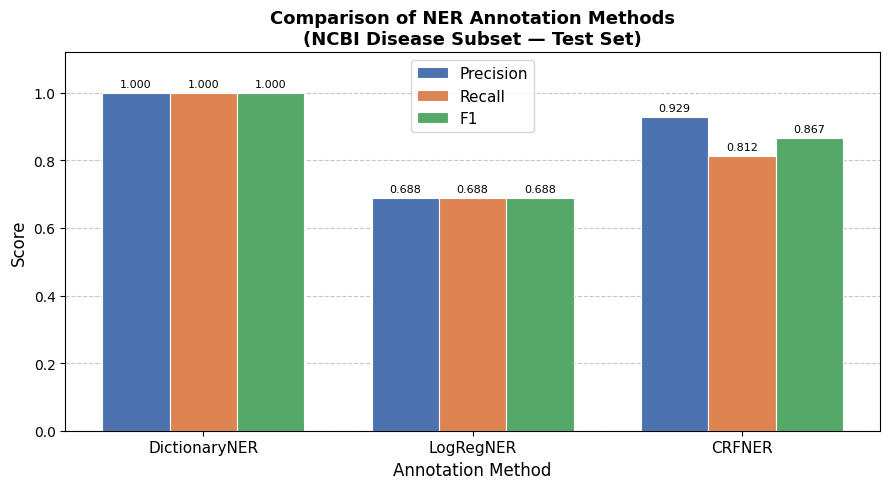

✅ Saved results/figure1_comparison.png


In [53]:
import matplotlib.pyplot as plt
import numpy as np

df_metrics = pd.read_csv('results/metrics.csv')
methods    = df_metrics['method'].tolist()
precision  = df_metrics['precision'].tolist()
recall     = df_metrics['recall'].tolist()
f1         = df_metrics['f1'].tolist()

x     = np.arange(len(methods))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - width, precision, width, label='Precision',
            color='#4C72B0', edgecolor='white', linewidth=0.8)
b2 = ax.bar(x,          recall,   width, label='Recall',
            color='#DD8452', edgecolor='white', linewidth=0.8)
b3 = ax.bar(x + width,  f1,       width, label='F1',
            color='#55A868', edgecolor='white', linewidth=0.8)

for bars in (b1, b2, b3):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f'{h:.3f}',
                    xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 3), textcoords='offset points',
                    ha='center', va='bottom', fontsize=8)

ax.set_xlabel('Annotation Method', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Comparison of NER Annotation Methods\n(NCBI Disease Subset — Test Set)',
             fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(methods, fontsize=11)
ax.set_ylim(0, 1.12)
ax.yaxis.grid(True, linestyle='--', alpha=0.7)
ax.set_axisbelow(True)
ax.legend(fontsize=11)
fig.tight_layout()
plt.savefig('results/figure1_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved results/figure1_comparison.png")

## Cell 12 — Figure 2: Ablation Study Line Plot

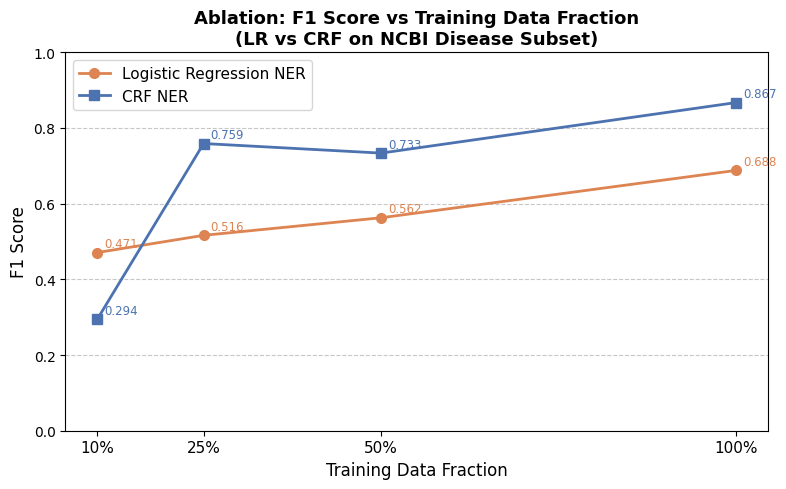

✅ Saved results/figure2_ablation.png


In [54]:
df_abl = pd.read_csv('results/ablation.csv')

fig, ax = plt.subplots(figsize=(8, 5))

colors  = {'LogRegNER': '#DD8452', 'CRFNER': '#4C72B0'}
markers = {'LogRegNER': 'o',       'CRFNER': 's'}
labels_map = {'LogRegNER': 'Logistic Regression NER',
              'CRFNER':    'CRF NER'}

for method in ['LogRegNER', 'CRFNER']:
    sub = df_abl[df_abl['method'] == method].sort_values('fraction')
    ax.plot(sub['fraction'], sub['f1'],
            marker=markers[method], color=colors[method],
            linewidth=2, markersize=7, label=labels_map[method])
    for _, row in sub.iterrows():
        ax.annotate(f"{row['f1']:.3f}",
                    xy=(row['fraction'], row['f1']),
                    xytext=(5, 4), textcoords='offset points',
                    fontsize=8.5, color=colors[method])

ax.set_xlabel('Training Data Fraction', fontsize=12)
ax.set_ylabel('F1 Score', fontsize=12)
ax.set_title('Ablation: F1 Score vs Training Data Fraction\n(LR vs CRF on NCBI Disease Subset)',
             fontsize=13, fontweight='bold')
fracs = sorted(df_abl['fraction'].unique())
ax.set_xticks(fracs)
ax.set_xticklabels([f'{int(f*100)}%' for f in fracs], fontsize=11)
ax.set_ylim(0, 1.0)
ax.yaxis.grid(True, linestyle='--', alpha=0.7)
ax.set_axisbelow(True)
ax.legend(fontsize=11)
fig.tight_layout()
plt.savefig('results/figure2_ablation.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Saved results/figure2_ablation.png")

## Cell 13 — Summary & Download Results

Run this cell to download `metrics.csv`, `ablation.csv`, and both figures from Colab.

In [55]:
# Print final summary
print("="*60)
print("  FINAL RESULTS SUMMARY")
print("="*60)
print(f"{'Method':<18} {'Precision':>10} {'Recall':>10} {'F1':>10}")
print("-"*50)
for name, m in [('DictionaryNER', dict_metrics),
                ('LogRegNER',    lr_metrics),
                ('CRFNER',       crf_metrics)]:
    print(f"{name:<18} {m['precision']:>10.4f} {m['recall']:>10.4f} {m['f1']:>10.4f}")
print("="*60)

print("\nAblation (F1 by training fraction):")
pivot = df_abl.pivot(index='fraction', columns='method', values='f1')
pivot.index = [f"{int(f*100)}%" for f in pivot.index]
pivot.columns.name = None
pivot.index.name = 'Fraction'
print(pivot.to_string())

# Download files from Colab
try:
    from google.colab import files
    for fname in ['results/metrics.csv', 'results/ablation.csv',
                  'results/figure1_comparison.png', 'results/figure2_ablation.png']:
        files.download(fname)
    print("\n✅ Files downloaded to your machine.")
except ImportError:
    print("\n(Not running in Colab — files saved to results/ folder.)")

  FINAL RESULTS SUMMARY
Method              Precision     Recall         F1
--------------------------------------------------
DictionaryNER          1.0000     1.0000     1.0000
LogRegNER              0.6875     0.6875     0.6875
CRFNER                 0.9286     0.8125     0.8667

Ablation (F1 by training fraction):
          CRFNER  LogRegNER
Fraction                   
10%       0.2941     0.4706
25%       0.7586     0.5161
50%       0.7333     0.5625
100%      0.8667     0.6875


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ Files downloaded to your machine.
